# EDA and Data Preparation: SISTIC snapshot to Culture Pass event knowledge base

This notebook explores the raw SISTIC data and explains every preparation decision. It calls the
same functions as the pipeline in `data_prep/`, so the notebook and the scripts always agree.
To rebuild the knowledge base without the notebook, run `python -m data_prep.run_all`.

| Step | What happens | Provenance of new values |
|---|---|---|
| 1 | Load the raw snapshot, remove duplicates, keep Culture Pass events | real |
| 2 | Clean: genre spellings, text, dates, prices | real (tidied or recovered) |
| 3 | Rule-derived fields: Culture Pass category, rating and language where the title gives evidence | rule-derived from real text |
| 4 | Spatial enrichment: venue coordinates from OneMap | real (OneMap) |
| 5 | Synthetic enrichment: the remaining Culture Pass filter columns | synthetic, rule-constrained |
| 6 | Assemble the catalogue, data dictionary and final checks | (documentation) |

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd

from config import RAW_JSON, REFERENCE_DATE, INTERIM_DIR, PROCESSED_DIR
from data_prep import (step1_load_and_filter as s1, step2_clean as s2, step3_rule_derived as s3,
                       step4_geocode as s4, step5_synthetic as s5, step6_build_catalogue as s6)
from data_prep.vocab import CP_CATEGORIES, LANGUAGES, GROUP_FRIENDLY, VENUE_ACCESS, CONTENT_ACCESS

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

# Chart style: one hue for single series, recessive grid and axes, text in ink colours.
BLUE, ORANGE = "#2a78d6", "#eb6834"
CATEGORY_COLOURS = dict(zip(["Music", "Visual Arts", "Heritage", "Theatre", "Dance",
                             "Literary Arts", "Films"],
                            ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
                             "#008300", "#6250d6"]))
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

## 1. First look at the raw snapshot

`Raw Data/sistic_events_raw.json` is the SISTIC events API output. It is never modified.
`Raw Data/sistic_events_raw.pdf` is a printed copy of the same rows and columns.

In [2]:
raw = s1.load_raw()
print(f"{len(raw)} rows x {raw.shape[1]} columns")
raw.head(3)

354 rows x 18 columns


,id,title,min_price,max_price,alias,start_date,end_date,event_date,venue_name,primary_genre,currency,currency_code,stixLite,tag_name,tag_colour,thumb_image,culture_pass,price
0,17411,SkyPark Observation Deck,31,126,cskypark2018,"Wed, 30 Nov 2022","Fri, 31 Dec 2027","Wed, 30 Nov - Fri, 31 Dec 2027","SkyPark Observation Deck, Level 56, Hotel Tower 3",Lifestyle/Leisure,S$,None,False,None,None,/sites/default/files/2025-01/Skypark (Peak)_horizontal-banner-436-...,False,S$31 - S$126
1,97867,Sampan Rides\r\n,11,16,sampanrides,"Mon, 09 Jun 2025","Sun, 23 Jun 2030","Mon, 09 Jun - Sun, 23 Jun 2030","The Shoppes at Marina Bay Sands, Basement 2, The Canal",Lifestyle/Leisure,S$,SGD,False,None,None,/sites/default/files/2025-01/MBSAttSampanHoriz.jpg,False,S$11 - S$16
2,135049,Craft Your Story: A Common Touch Pottery Workshop,100,None,lite_commonTouchsep25,"Mon, 01 Sep 2025","Mon, 28 Sep 2026","Mon, 01 Sep - Mon, 28 Sep 2026",COMMON TOUCH,"Course, Training or Workshop",S$,SGD,True,None,None,/sites/default/files/2025-07/Event Listing Page (1).png,True,NaN


In [3]:
# Missing values per column (blank, None or empty), across all 354 raw rows.
missing = raw.apply(lambda s: s.isna() | s.astype(str).str.strip().isin(["", "None"])).sum()
pd.DataFrame({"missing": missing, "percent": (100 * missing / len(raw)).round(1)}).query("missing > 0")

,missing,percent
min_price,30,8.5
max_price,118,33.3
event_date,1,0.3
currency_code,6,1.7
tag_name,347,98.0
tag_colour,347,98.0
price,118,33.3


These counts match the team's September draft *Data Collection And Challenges*
(30 missing `min_price`, 118 missing `max_price`, 6 missing `currency_code`).
The snapshot was pulled on **11 Sep 2026**, the day that draft was saved.

**Decision: the chatbot's "today" is 11 Sep 2026** (`REFERENCE_DATE` in `config.py`).
Every Culture Pass event in the snapshot is still running on that date.

In [4]:
dupes = raw[raw.duplicated("id", keep=False)].sort_values("id")
print(f"{raw['id'].duplicated().sum()} duplicate rows; the repeated rows are identical: "
      f"{dupes.groupby('id').nunique().le(1).all().all()}")
dupes[["id", "title", "culture_pass"]]

2 duplicate rows; the repeated rows are identical: True


,id,title,culture_pass
99,161788,DIFFERENT: Drift,True
100,161788,DIFFERENT: Drift,True
159,166953,Pub Choir - Just Think About It World Tour,False
160,166953,Pub Choir - Just Think About It World Tour,False


## 2. Step 1: remove duplicates and keep Culture Pass events

SISTIC's `culture_pass` flag is real data. Keeping only flagged events means every recommendation
the chatbot makes is a real Culture Pass event as of the snapshot date.

In [5]:
unique = s1.remove_duplicates(raw)
cp_raw = s1.keep_culture_pass(unique)
pd.Series({"raw rows": len(raw), "unique events": len(unique),
           "Culture Pass flagged": len(cp_raw), "not flagged (dropped)": len(unique) - len(cp_raw)})

raw rows                 354
unique events            352
Culture Pass flagged     147
not flagged (dropped)    205
dtype: int64

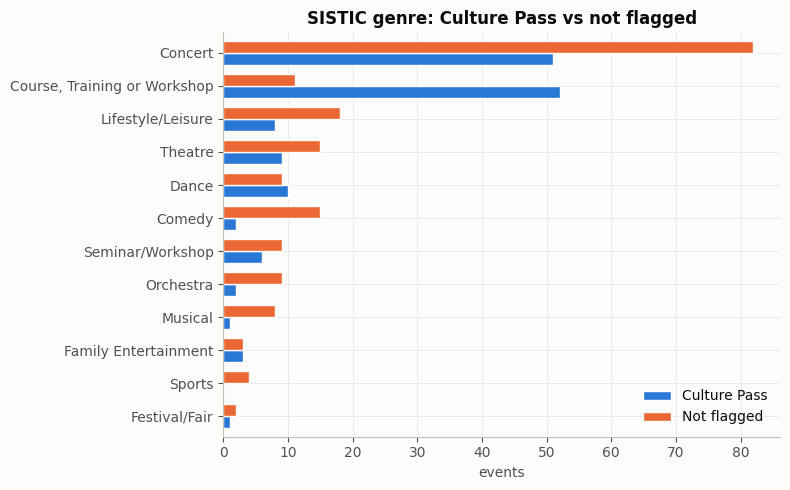

In [6]:
# How do flagged and unflagged events differ? (SISTIC genres, top 12)
compare = (unique.assign(group=unique["culture_pass"].map({True: "Culture Pass", False: "Not flagged"}))
                 .groupby(["primary_genre", "group"]).size().unstack(fill_value=0))
compare = compare.loc[compare.sum(axis=1).sort_values().index[-12:]]
ax = compare[["Culture Pass", "Not flagged"]].plot.barh(color=[BLUE, ORANGE], width=0.75,
                                                         figsize=(8, 5), edgecolor="#fcfcfb")
ax.set(title="SISTIC genre: Culture Pass vs not flagged", xlabel="events", ylabel="")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()

Culture Pass events lean heavily towards workshops and classical concerts. Comedy, musicals and
pop concerts are mostly *not* flagged. The unflagged events stay out of the catalogue, but they
are useful later as negative test cases: the chatbot must never recommend them.

## 3. Step 2: data quality issues and cleaning decisions

In [7]:
cp_raw["primary_genre"].value_counts()

primary_genre
Course, Training or Workshop    52
Concert                         51
Dance                           10
Theatre                          9
Lifestyle/Leisure                8
Seminar/Workshop                 6
Family Entertainment             3
Comedy                           2
Orchestra                        2
Food & Beverage                  1
concert                          1
Musical                          1
Festival/Fair                    1
Name: count, dtype: int64

**Genre labels are inconsistent.** `concert` and `Concert` are the same label, and two different
labels (`Course, Training or Workshop`, `Seminar/Workshop`) both mean a workshop.
**Decision:** keep SISTIC's original in `sistic_genre_raw` and add a merged `sistic_genre`.

In [8]:
no_min = cp_raw[cp_raw["min_price"].isna()]
no_min[["id", "title", "min_price", "max_price", "price"]]

,id,title,min_price,max_price,price
9,134395,Travel Sketching Workshop: Capturing Singapores Heritage,None,90,S$90
70,169880,Legacy Mansion 《惜怀。古宅》,None,55,S$55
79,169963,Opus 26,None,15,S$15
117,166140,Heritage Journey with Eng Tiang Huat Chinese Cultural Shop,None,38,S$38
120,170226,BHCC 50th Anniversary Gala Concert,None,30,S$30
127,155111,"SSO Chamber Series: Lan Shui conducts Stravinsky, Schoenberg and M...",None,40,S$40
142,155113,SSO Chamber Series: Divertissement,None,20,S$20
145,155114,SSO Chamber Series: Music for VIPs,None,20,S$20


**The eight "missing" prices are not really missing.** Each event has one ticket price, stored in
`max_price` and in the `price` text. **Decision:** recover `min_price` from those SISTIC fields
(flagged in `min_price_recovered`). Nothing is guessed, and no blank price ever becomes $0.

`max_price` is blank for 77 events. SISTIC shows only a "from" price for them, so it stays blank
(unknown). The Culture Pass price filter works on the lowest price, which every event has.

In [9]:
# Columns that carry no information once only Culture Pass events remain.
pd.Series(s2.DROP_COLUMNS, name="reason dropped").to_frame()

,reason dropped
culture_pass,always True after Step 1
currency,always S$ for Culture Pass events
currency_code,always SGD for Culture Pass events
tag_name,empty for every Culture Pass event
tag_colour,empty for every Culture Pass event
event_date,a text copy of start_date and end_date
price,"only used to recover missing min_price, then redundant"
stixLite,"internal SISTIC ticketing flag, not an event attribute"


In [10]:
clean = s2.clean(cp_raw)
s2.check(clean)   # stops here if any assumption fails
clean.head()

,event_id,title,sistic_genre,sistic_genre_raw,venue_name,start_date,end_date,min_price,max_price,min_price_recovered,sistic_alias,thumb_image
0,135049,Craft Your Story: A Common Touch Pottery Workshop,Workshop,"Course, Training or Workshop",COMMON TOUCH,2025-09-01,2026-09-28,100.0,NaN,False,lite_commonTouchsep25,/sites/default/files/2025-07/Event Listing Page (1).png
1,135570,Introduction to Digital Art Workshop,Workshop,"Course, Training or Workshop",Visual Arts Centre at Dhoby Ghaut,2025-09-01,2026-12-31,90.0,NaN,False,lite_vacdigitalart3,/sites/default/files/2025-07/SISTIC (event listing)_0.jpg
2,136331,"Peranakan Culture & Heritage, The Crazy Rich Asians",Lifestyle/Leisure,Lifestyle/Leisure,Peranakan Mansion in Joo Chiat,2025-09-02,2026-12-31,83.0,NaN,False,lite_peranakanculturekebaya1928,/sites/default/files/2025-08/3Y7A2722c.JPG
3,134893,Still life drawing and sketching workshop,Workshop,"Course, Training or Workshop",Visual Arts Centre at Dhoby Ghaut,2025-09-04,2026-12-31,50.0,NaN,False,lite_vacdrawingandsketching8,/sites/default/files/2026-09/SISTIC (event listing) 436px (w) x 32...
4,131859,Sauce Discovery Tour,Workshop,"Course, Training or Workshop",18 Chin Bee Avenue Singapore 619940,2025-09-06,2026-12-12,39.0,NaN,False,lite_saucediscoverytour01,/sites/default/files/2025-05/Workshop 4 436px (w) x 326px (h).jpg


In [11]:
# Same title, different listing: recurring classes offered at several branches or dates.
repeats = clean[clean["title"].duplicated(keep=False)].sort_values("title")
repeats[["event_id", "title", "venue_name", "start_date", "end_date"]]

,event_id,title,venue_name,start_date,end_date


**Decision:** these stay as separate events, because each listing has its own venue or dates.
Overseas venues and cancelled events were also checked: none are flagged as Culture Pass.

## 4. Exploring the clean Culture Pass events

min_price
<= $25     45
$26-50     45
$51-100    55
> $100      2
Name: count, dtype: int64

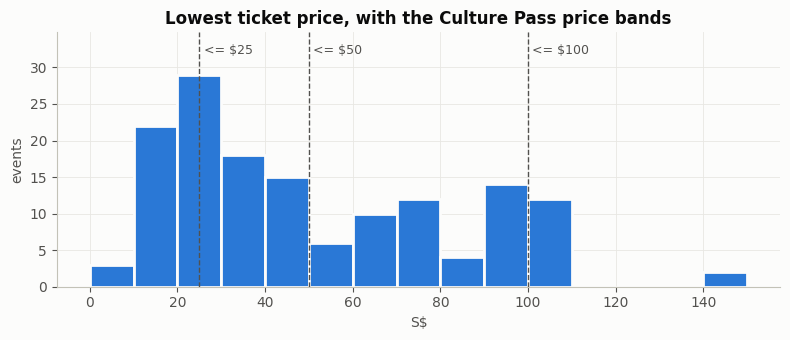

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.5))
heights, _, _ = ax.hist(clean["min_price"], bins=range(0, 160, 10), color=BLUE,
                        edgecolor="#fcfcfb", linewidth=2)
ax.set_ylim(0, heights.max() * 1.2)
for band in [25, 50, 100]:
    ax.axvline(band, color="#52514e", linewidth=1, linestyle="--")
    ax.text(band + 1, heights.max() * 1.1, f"<= ${band}", color="#52514e", fontsize=9)
ax.set(title="Lowest ticket price, with the Culture Pass price bands", xlabel="S$", ylabel="events")
plt.tight_layout()
bands = pd.cut(clean["min_price"], [0, 25, 50, 100, 220], labels=["<= $25", "$26-50", "$51-100", "> $100"])
bands.value_counts().sort_index()

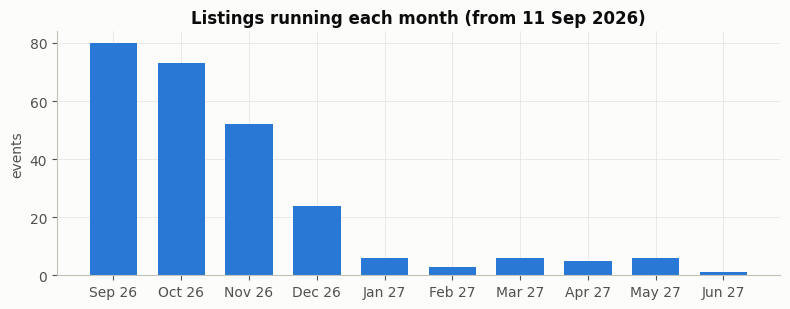

In [13]:
# How many listings are running in each month after the reference date?
months = pd.period_range(pd.Timestamp(REFERENCE_DATE), "2027-06", freq="M")
start, end = pd.to_datetime(clean["start_date"]), pd.to_datetime(clean["end_date"])
running = [((start <= m.end_time) & (end >= m.start_time)).sum() for m in months]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar([m.strftime("%b %y") for m in months], running, color=BLUE, width=0.7)
ax.set(title=f"Listings running each month (from {REFERENCE_DATE:%d %b %Y})", ylabel="events")
plt.tight_layout()

Most listings run within the next three months. Some workshop listings span a whole year;
their date range means "bookable on some dates within", not "on every day". The chatbot's date
reasoning needs to treat long ranges that way.

In [14]:
top_venues = clean["venue_name"].value_counts().head(8)
top_venues

venue_name
Victoria Concert Hall                                                     18
Esplanade Concert Hall                                                    18
Artify Studio, Textile Centre, #12-07                                     17
Esplanade Recital Studio                                                   7
Visual Arts Centre at Dhoby Ghaut                                          5
18 Chin Bee Avenue Singapore 619940                                        3
Singapore Chinese Cultural Centre Auditorium, Level 9 新加坡华族文化中心表演厅, 九楼     3
TAS Studio                                                                 3
Name: count, dtype: int64

## 5. Step 3: rule-derived fields

The Culture Pass site files events under seven categories. SISTIC uses its own genres, so each
event is mapped by written-down rules (see `data_prep/step3_rule_derived.py`):

* Performance genres map directly: Concert to Music, Dance to Dance, Theatre/Musical/Comedy to Theatre.
* Workshops are filed under the art form they teach, using title keywords
  (guitar to Music, painting or clay to Visual Arts, kebaya or heritage trail to Heritage).

Every event records the rule that categorised it in `cp_category_rule`. The title also gives
real evidence for a few ratings (`[G]`, `[Rating: TBA]`) and for language
(Chinese characters, Malay or Tamil words).

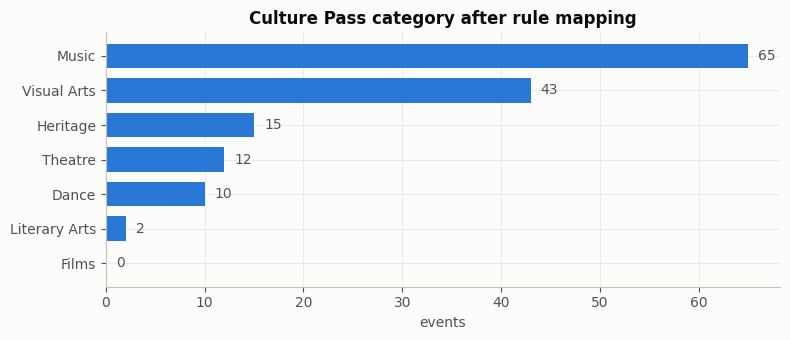

In [15]:
rules = s3.derive(clean)
s3.check(rules)
counts = rules["cp_category"].value_counts().reindex(CP_CATEGORIES, fill_value=0).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(counts.index, counts.values, color=BLUE, height=0.7)
for y, v in enumerate(counts.values):
    ax.text(v + 1, y, str(v), va="center", color="#52514e")
ax.set(title="Culture Pass category after rule mapping", xlabel="events")
plt.tight_layout()

**Thin categories.** Music and Visual Arts make up about three quarters of the catalogue.
Literary Arts has two events and **Films has none**. Test scenarios must be designed around what
actually exists, and a request for films should get an honest "nothing available" answer.

In [16]:
rules.groupby("cp_category_rule").size().rename("events").to_frame()

,events
cp_category_rule,
G1-genre:Comedy,2
G1-genre:Concert,52
G1-genre:Dance,10
G1-genre:Musical,1
G1-genre:Orchestra,2
G1-genre:Theatre,9
G2-family-music,3
K1-music-skill,8
K2-literary,2


In [17]:
# Workshops and other non-performance events: check each mapping by eye.
(rules[~rules["cp_category_rule"].str.startswith("G1")]
      [["title", "sistic_genre", "cp_category", "cp_category_rule"]]
      .sort_values(["cp_category", "title"]))

,title,sistic_genre,cp_category,cp_category_rule
6,Art of Nanyang Sauce,Workshop,Heritage,K4-heritage
44,Chinese Penjing in Singapore,Workshop,Heritage,K4-heritage
11,Experiencing Nyonya Kebaya Fashion,Workshop,Heritage,K4-heritage
117,Heritage Journey with Eng Tiang Huat Chinese Cultural Shop,Lifestyle/Leisure,Heritage,K4-heritage
7,Heritage in a Cup,Workshop,Heritage,K4-heritage
...,...,...,...,...
3,Still life drawing and sketching workshop,Workshop,Visual Arts,K3-visual-craft
69,The Makers' Loft: Nagomi Art Workshop,Workshop,Visual Arts,K3-visual-craft
9,Travel Sketching Workshop: Capturing Singapores Heritage,Workshop,Visual Arts,K3-visual-craft
54,Vase of Daisies Palette-Knife Painting Workshop,Workshop,Visual Arts,K3-visual-craft


In [18]:
rules.loc[rules["language_source"].notna(),
          ["title", "lang_mandarin", "lang_malay", "lang_tamil"]]

,title,lang_mandarin,lang_malay,lang_tamil
50,我狮城，我街道，我美食 Stories & Flavours of the City: Streets & Places of SG 2,True,False,False
61,Batu Bo Makan Gegat (The Impossible),False,True,False
62,菜鸟相声社 三周年相声专场 Cainiao Crosstalk Club 3rd Anniversary Performance,True,False,False
65,Paruvangal,False,False,True
70,Legacy Mansion 《惜怀。古宅》,True,False,False
73,Happy Sing-Along 欢喜来唱歌 2026,True,False,False
76,新传媒 LOVE 972 庆生音乐剧 《新十兄弟》Legend of the Ten Bruh,True,False,False
78,Echoes of the Screen: Reimagined Drama Classics 《荧幕回声：经典剧集音乐会》,True,False,False
83,阿水单口喜剧专场 Ah Shui Stand-up Comedy Special,True,False,False
85,Manikandan,False,False,True


## 6. Step 4: spatial enrichment with OneMap

Each venue is looked up once with the OneMap Search API (Singapore Land Authority). SISTIC venue
names are messy, so the script tries simpler forms of each name. For venues OneMap cannot match,
the team adds a search phrase or postal code to `Curated Data/venue_overrides.csv`, with its source.
Results are saved, so this notebook does not call OneMap again.

In [19]:
venues_geo = s4.run()   # reuses the saved results; s4.run(refresh=True) retries missing venues
venues_geo["geocode_status"].value_counts().to_frame("venues")

Step 4: using saved geocoding for 62 venues {'found': 57, 'not_found': 4, 'not_a_place': 1} (refresh=True to retry)


,venues
geocode_status,
found,57
not_found,4
not_a_place,1


In [20]:
venues_geo.loc[venues_geo["geocode_status"] != "found", ["venue_name", "geocode_status"]]

,venue_name,geocode_status
10,TAS Studio,not_found
13,TCA Prologue Cafe (Tea. Coffee. Artisans),not_found
24,Cloud Nine Private Dining,not_found
31,Flock at Kampong Java - The Hall,not_found
60,Various Venues,not_a_place


Twelve venues that version 1 could not place were resolved from published addresses (sources are
recorded in the overrides file). Three venues use a nearby landmark (`location_precision = approximate`).
Four small venues could not be confirmed, and "Various Venues" is not a single place.
Their events stay in the catalogue with blank coordinates, so the chatbot must say their location
is unknown rather than guess.

## 7. Step 5: synthetic enrichment

The Culture Pass site lets users filter by things SISTIC does not record. Each filter on the site
was sorted into one of two kinds (`data_prep/vocab.py`):

* **Stored**: an attribute of the event, which needs its own column. Category, rating, language,
  group-friendly tags, venue accessibility and content accessibility.
* **Computed**: answered at question time from columns already present. Date filters
  ("This weekend" depends on today's date), price bands and sorting.

Stored filters that no real field supports are filled synthetically:
hard rules first, then a seeded draw whose probability depends on the event's category or venue type.

In [21]:
events_syn, venues_syn = s5.run()

Step 5: rating sources {'SYNTHETIC': 141, 'RULE_DERIVED:children': 4, 'RULE_DERIVED:title': 2} | language sources {'ASSUMED_DEFAULT:English': 129, 'RULE_DERIVED:title': 18}


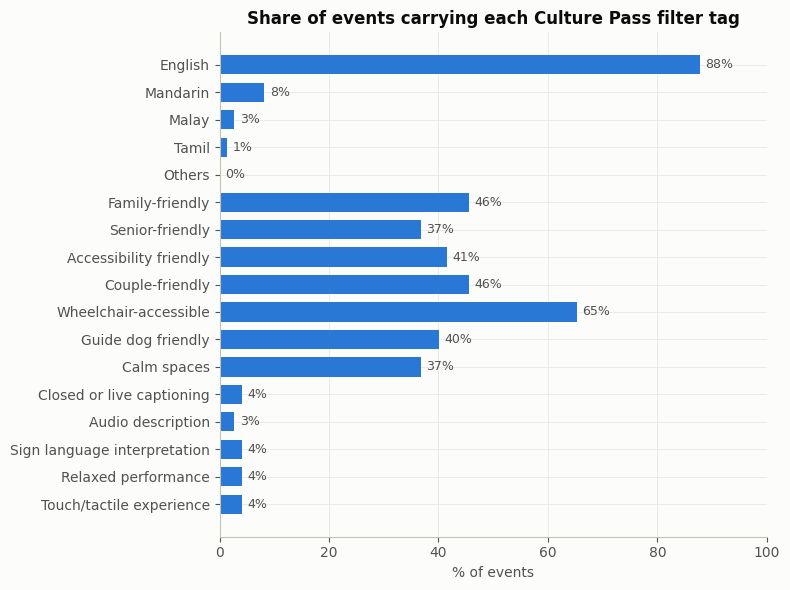

In [22]:
flag_cols = {**LANGUAGES, **GROUP_FRIENDLY, **VENUE_ACCESS, **CONTENT_ACCESS}
share = (events_syn[list(flag_cols)].eq(True).mean() * 100).rename(index=flag_cols)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(share.index[::-1], share.values[::-1], color=BLUE, height=0.7)
for y, v in enumerate(share.values[::-1]):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", color="#52514e", fontsize=9)
ax.set(title="Share of events carrying each Culture Pass filter tag", xlabel="% of events", xlim=(0, 100))
plt.tight_layout()

In [23]:
pd.crosstab(events_syn["rating"], events_syn["rating_source"], margins=True)

rating_source,RULE_DERIVED:children,RULE_DERIVED:title,SYNTHETIC,All
rating,,,,
12 and Above,0,0,5,5
13 and Above,0,0,3,3
6 and Above,0,0,22,22
Advisory,0,0,6,6
Advisory 16,0,0,2,2
General,4,1,98,103
PG,0,0,1,1
PG13,0,0,1,1
TBA,0,1,3,4


In [24]:
# The consistency rules hold: no adult or teen rating is tagged family-friendly.
pd.crosstab(events_syn["rating"], events_syn["gf_family"])

gf_family,False,True
rating,,
12 and Above,5,0
13 and Above,3,0
6 and Above,8,14
Advisory,2,4
Advisory 16,2,0
General,54,49
PG,1,0
PG13,1,0
TBA,4,0


## 8. Step 6: the finished knowledge base

In [25]:
catalogue = s6.run()
catalogue.head()

Step 6: 147 events, 62 venues, all unique | all events still running on the reference date 2026-09-11 | all prices within the Culture Pass slider range $0-$220 | 140 events have coordinates inside Singapore; 7 events at 5 venues have none


,event_id,title,cp_category,cp_category_rule,interest_tags,sistic_genre,sistic_genre_raw,start_date,end_date,min_price,...,venue_name,venue_type,venue_address,postal_code,lat,lon,location_precision,geocode_status,sistic_alias,thumb_image
0,135049,Craft Your Story: A Common Touch Pottery Workshop,Visual Arts,K3-visual-craft,pottery and clay,Workshop,"Course, Training or Workshop",2025-09-01,2026-09-28,100.0,...,COMMON TOUCH,studio_or_shop,44 KALLANG PLACE FOUR STAR BUILDING SINGAPORE 339172,339172,1.313497,103.868019,exact,found,lite_commonTouchsep25,/sites/default/files/2025-07/Event Listing Page (1).png
1,135570,Introduction to Digital Art Workshop,Visual Arts,K3-visual-craft,digital art,Workshop,"Course, Training or Workshop",2025-09-01,2026-12-31,90.0,...,Visual Arts Centre at Dhoby Ghaut,arts_centre_or_gallery,10 PENANG ROAD SINGAPORE 238469,238469,1.298452,103.846112,exact,found,lite_vacdigitalart3,/sites/default/files/2025-07/SISTIC (event listing)_0.jpg
2,136331,"Peranakan Culture & Heritage, The Crazy Rich Asians",Heritage,K4-heritage,history and heritage|peranakan culture,Lifestyle/Leisure,Lifestyle/Leisure,2025-09-02,2026-12-31,83.0,...,Peranakan Mansion in Joo Chiat,museum_or_heritage_site,1 JOO CHIAT ROAD CASSANDRA JOO CHIAT COMPLEX,NIL,1.315999,103.898327,approximate,found,lite_peranakanculturekebaya1928,/sites/default/files/2025-08/3Y7A2722c.JPG
3,134893,Still life drawing and sketching workshop,Visual Arts,K3-visual-craft,drawing,Workshop,"Course, Training or Workshop",2025-09-04,2026-12-31,50.0,...,Visual Arts Centre at Dhoby Ghaut,arts_centre_or_gallery,10 PENANG ROAD SINGAPORE 238469,238469,1.298452,103.846112,exact,found,lite_vacdrawingandsketching8,/sites/default/files/2026-09/SISTIC (event listing) 436px (w) x 32...
4,131859,Sauce Discovery Tour,Heritage,K4-heritage,food heritage,Workshop,"Course, Training or Workshop",2025-09-06,2026-12-12,39.0,...,18 Chin Bee Avenue Singapore 619940,studio_or_shop,18 CHIN BEE AVENUE SINGAPORE 619940,619940,1.333232,103.711109,exact,found,lite_saucediscoverytour01,/sites/default/files/2025-05/Workshop 4 436px (w) x 326px (h).jpg


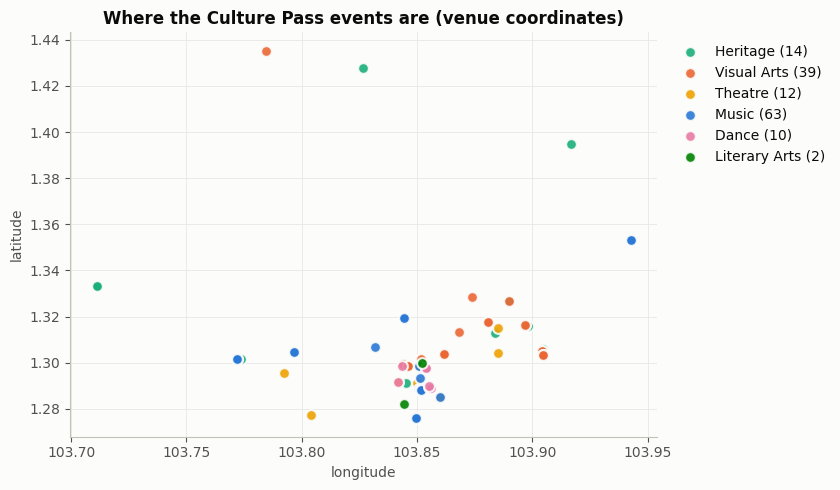

In [26]:
located = catalogue.dropna(subset=["lat", "lon"])
fig, ax = plt.subplots(figsize=(8, 5))
for cat in [c for c in CP_CATEGORIES if c in set(located["cp_category"])]:
    pts = located[located["cp_category"] == cat]
    ax.scatter(pts["lon"], pts["lat"], s=60, color=CATEGORY_COLOURS[cat], label=f"{cat} ({len(pts)})",
               edgecolor="#fcfcfb", linewidth=1.5, alpha=0.9)
ax.set(title="Where the Culture Pass events are (venue coordinates)", xlabel="longitude", ylabel="latitude")
ax.set_aspect("equal")
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()

In [27]:
dictionary = pd.read_csv(PROCESSED_DIR / "data_dictionary.csv")
dictionary.groupby("provenance").size().rename("columns").to_frame()

,columns
provenance,
MIXED (see *_source),6
ONEMAP_REAL,4
PIPELINE_METADATA,7
RULE_DERIVED,3
SISTIC_REAL,11
SYNTHETIC,14
SYNTHETIC_DERIVED,1


In [28]:
dictionary

,column,provenance,meaning_and_method,allowed_values
0,event_id,SISTIC_REAL,"SISTIC event ID, unique per listing",integer
1,title,SISTIC_REAL,Event title; zero-width and non-breaking spaces removed,text
2,cp_category,RULE_DERIVED,Culture Pass genre. Performance genres map directly; workshops are...,Heritage | Visual Arts | Theatre | Music | Dance | Films | Literar...
3,cp_category_rule,PIPELINE_METADATA,ID of the Step 3 rule that set cp_category,G1/G2/K1-K4/F1
4,interest_tags,RULE_DERIVED,"Interest concepts the event is about, from title keywords and SIST...",'|'-separated concepts from data_prep/vocab.py INTEREST_CONCEPTS
5,sistic_genre,SISTIC_REAL,SISTIC genre with spellings merged (concert->Concert; two workshop...,text
6,sistic_genre_raw,SISTIC_REAL,SISTIC genre exactly as downloaded,text
7,start_date,SISTIC_REAL,First date of the listing,YYYY-MM-DD
8,end_date,SISTIC_REAL,Last date of the listing. Long ranges mean 'available on some date...,YYYY-MM-DD
9,min_price,SISTIC_REAL,Lowest ticket price in S$. 8 values recovered from SISTIC's own ma...,number; CP price filter uses this


## Summary of decisions

1. **Scope:** only events SISTIC flags as Culture Pass (147 of 352 unique events).
2. **Reference date:** 11 Sep 2026, the date the snapshot was pulled.
3. **Duplicates:** two repeated rows removed, one of them a Culture Pass event.
4. **Prices:** eight lowest prices recovered from SISTIC's own fields; unknown prices never become $0.
5. **Genres:** spellings merged; mapped to the seven Culture Pass categories by traceable rules.
6. **Location:** 57 of 62 venues located with OneMap; the rest stay blank, never guessed.
7. **Synthetic columns:** every remaining Culture Pass filter, generated by rules plus seeded draws,
   and tagged so results can always be traced back to real or invented data.